# 🌌 Lesson 3: DBSCAN: Clustering by Density
### *"Cities are crowds of lights. Everything else is just a lonely light."*

**Week 10 · Session 3 of 6 · ⏱ about 90 minutes**

---

### 🎯 Learning objectives
By the end of this lesson you will be able to:
1. Explain DBSCAN using **core, border, and noise** points.
2. Describe what `eps` and `min_samples` mean and choose them with a **k-distance plot**.
3. Implement DBSCAN **from scratch** and verify against scikit-learn.
4. Explain where DBSCAN **beats** K-Means (any shape, noise): and where it **struggles** (varying density, high dimensions).
5. Cluster **geographic coordinates** with the haversine distance.
6. Use the **noise label** as a *finding*, not an inconvenience.

### 📋 Prerequisites
Lessons 1–2. You should be comfortable with scaling and distance.

### 🔙 Where we are
K-Means: needs *k*, only round clusters, no concept of outliers. Hierarchical: great for small data, greedy. Today's algorithm fixes the first three K-Means complaints at once.

## 1 · The idea: look at the night sky from space 🛰️

From orbit at night, **cities** appear as dense glowing blobs. They have all sorts of shapes: long strips along coasts, sprawling rings. Between them are scattered **lone lights**: a farmhouse, a petrol station. Nobody told you how many cities exist, yet your eye finds them instantly.

What your eye does is **density**: *"this area is packed with lights; that area is nearly empty."*

> 💡 **Intuition.** A **cluster** is a region where points are packed together, separated from other clusters by **sparse** regions. Points in sparse regions are **noise**.

**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*, 1996) formalises this with just **two knobs**:

| Parameter | Meaning | Analogy |
|---|---|---|
| **`eps`** (ε) | The *radius* of a neighbourhood | "How far can you reach to shake hands?" |
| **`min_samples`** | The minimum number of points (including itself) in a neighbourhood to count as "crowded" | "How many people make a crowd?" |

Using these, every point gets one of **three roles**:

| Role | Definition | Plain English |
|---|---|---|
| 🟦 **Core point** | Has ≥ `min_samples` points (itself included) within distance `eps` | Standing in a crowd |
| 🟧 **Border point** | *Not* core, but within `eps` of a core point | On the edge of the crowd |
| ⬜ **Noise point** | Neither | Standing alone in the field |

**Clusters** are formed by *chaining* core points: if two core points are within `eps` of each other, they're in the same cluster; border points join the cluster of a nearby core point.

## 2 · The algorithm

```
for each point p not yet assigned:
    if p is not a core point: skip it (it might become a border point later, or stay noise)
    else:
        start a NEW cluster with p
        put every neighbour of p into a "to-visit" queue
        while the queue is not empty:
            take q from the queue; give q this cluster's label if it has none
            if q is a core point:  add all of q's neighbours to the queue   # the cluster keeps growing
            # border points join the cluster but do NOT recruit further
```

It's like a **rumour spreading through a crowd**: it only passes along through people who are in a crowd (core points). Someone on the fringe hears it but can't pass it on.

Everything *not* reached by any rumour is noise.

### What makes DBSCAN special
- ✅ **No need to specify the number of clusters.** It finds as many as exist.
- ✅ **Any shape**: crescents, rings, long curves.
- ✅ **Noise-aware**: outliers get label **−1** instead of being forced into a cluster.
- ✅ Only two parameters, both with physical meaning.
- ⚠️ But those parameters are **delicate** (we'll see), and a *single* `eps` assumes all clusters have **similar density**.

## 3 · Setup and a hand-sized example ✏️

Nine points. We'll classify each by hand, then let the computer check.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons, make_blobs, make_circles
from sklearn.metrics import adjusted_rand_score
from course_utils import set_style, load, check, plot_clusters_2d
set_style()
RANDOM_STATE = 42

P = np.array([[0, 0], [1, 0], [0, 1], [1, 1], [2, 1],      # a little crowd
              [3.2, 1.0],                                  # someone at the edge of it
              [5, 5], [5, 6],                              # a pair (too few to be a crowd)
              [10, 10]])                                   # a lone light
EPS, MIN_SAMPLES = 1.5, 3

D = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(axis=2))
n_in_radius = (D <= EPS).sum(axis=1)                        # includes the point itself
print("Neighbours within eps (self included):", n_in_radius)
print("Core points (>= min_samples)         :", np.where(n_in_radius >= MIN_SAMPLES)[0])

Neighbours within eps (self included): [4 5 4 5 4 2 2 2 1]
Core points (>= min_samples)         : [0 1 2 3 4]


**By hand:** points 0–4 each have ≥ 3 points in reach → **core**. Point 5 (3.2, 1.0) only reaches itself and point 4 (2 points < 3) → *not* core, but it's within reach of core point 4 → **border**. Points 6 and 7 reach only each other (2 points) → not core and not near any core → **noise**. Point 8 is alone → **noise**.

      x     y  neighbours    role  label
0   0.0   0.0           4    core      0
1   1.0   0.0           5    core      0
2   0.0   1.0           4    core      0
3   1.0   1.0           5    core      0
4   2.0   1.0           4    core      0
5   3.2   1.0           2  border      0
6   5.0   5.0           2   noise     -1
7   5.0   6.0           2   noise     -1
8  10.0  10.0           1   noise     -1


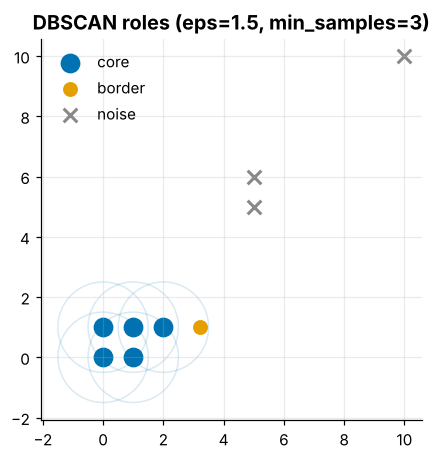

In [2]:
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(P)
db_hand = db            # keep scikit-learn's answer around: Exercise 1 compares against it
role = np.array(["noise"] * len(P), dtype=object)
role[db.labels_ >= 0] = "border"
role[db.core_sample_indices_] = "core"
print(pd.DataFrame({"x": P[:, 0], "y": P[:, 1], "neighbours": n_in_radius, "role": role, "label": db.labels_}))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
styles = {"core": ("o", 120, "#0072B2"), "border": ("o", 60, "#E69F00"), "noise": ("x", 80, "#888")}
for r, (mk, sz, col) in styles.items():
    pts = P[role == r]; ax.scatter(pts[:, 0], pts[:, 1], marker=mk, s=sz, color=col, label=r, linewidths=2)
for p in P[db.core_sample_indices_]:
    ax.add_patch(plt.Circle(p, EPS, fill=False, color="#0072B2", alpha=.15))
ax.set_aspect("equal"); ax.set_title(f"DBSCAN roles (eps={EPS}, min_samples={MIN_SAMPLES})"); ax.legend(); plt.show()

## 4 · Build DBSCAN from scratch 🔧

Now the whole algorithm in ~20 lines. It follows the pseudocode exactly.

In [3]:
def dbscan_scratch(X, eps, min_samples):
    """Minimal DBSCAN. Returns (labels, is_core). Noise is labelled -1."""
    X = np.asarray(X, float)
    n = len(X)
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
    neighbours = [np.where(D[i] <= eps)[0] for i in range(n)]          # who is within reach of whom
    is_core = np.array([len(nb) >= min_samples for nb in neighbours])  # the 'crowd' test

    labels = np.full(n, -1)                       # everyone starts as noise
    cluster_id = 0
    for i in range(n):
        if labels[i] != -1 or not is_core[i]:
            continue                              # already claimed, or can't start a cluster
        labels[i] = cluster_id
        queue = [i]
        while queue:
            p = queue.pop()
            if not is_core[p]:
                continue                          # border points join the cluster but don't recruit
            for q in neighbours[p]:
                if labels[q] == -1:
                    labels[q] = cluster_id        # join the cluster
                    queue.append(q)               # and maybe recruit others
        cluster_id += 1
    return labels, is_core


X_moons, y_moons = make_moons(n_samples=400, noise=0.07, random_state=RANDOM_STATE)
lab_s, core_s = dbscan_scratch(X_moons, eps=0.2, min_samples=5)
lab_sk = DBSCAN(eps=0.2, min_samples=5).fit_predict(X_moons)

print("clusters found (ours / sklearn):", len(set(lab_s) - {-1}), "/", len(set(lab_sk) - {-1}))
print("noise points   (ours / sklearn):", (lab_s == -1).sum(), "/", (lab_sk == -1).sum())
print("agreement (Adjusted Rand Index):", round(adjusted_rand_score(lab_s, lab_sk), 4))

clusters found (ours / sklearn): 2 / 2
noise points   (ours / sklearn): 1 / 1
agreement (Adjusted Rand Index): 1.0


> 🧠 **Remember.** Why might our result differ slightly from scikit-learn's on *border* points? A border point can be within reach of core points from **two** different clusters. Whichever cluster reaches it first claims it, so results can depend on the point order. Core points and noise are always identical; only these ambiguous border points can legitimately differ.

## 5 · DBSCAN vs K-Means on awkward shapes 🆚

Remember Lesson 1's moons, where K-Means sliced straight through them? Same data, plus a noisy **blobs + scattered noise** set:

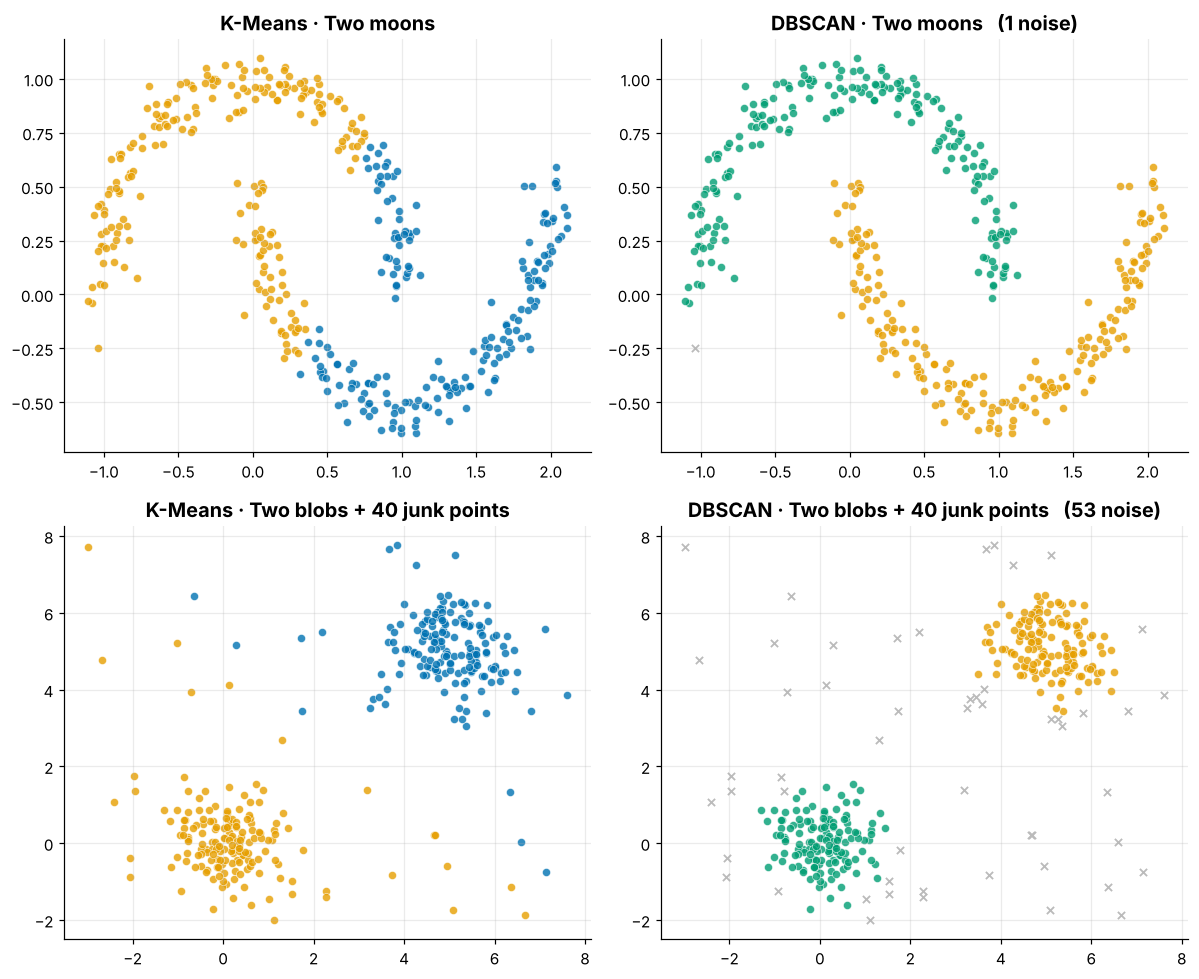

In [4]:
rng = np.random.default_rng(3)
X_blobs, _ = make_blobs(300, centers=[[0, 0], [5, 5]], cluster_std=0.7, random_state=1)
X_noisy = np.vstack([X_blobs, rng.uniform(-3, 8, size=(40, 2))])            # + 40 random 'junk' points

cases = [("Two moons", X_moons, 2, dict(eps=0.2, min_samples=5)),
         ("Two blobs + 40 junk points", X_noisy, 2, dict(eps=0.55, min_samples=8))]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, (name, data, k, params) in enumerate(cases):
    km_lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(data)
    db_lab = DBSCAN(**params).fit_predict(data)
    plot_clusters_2d(data, km_lab, ax=axes[r, 0], title=f"K-Means · {name}")
    plot_clusters_2d(data, db_lab, ax=axes[r, 1], title=f"DBSCAN · {name}   ({(db_lab == -1).sum()} noise)")
    for c in range(2): axes[r, c].legend().set_visible(False)
plt.tight_layout(); plt.show()

- **Top row:** DBSCAN follows each crescent perfectly; K-Means can't.
- **Bottom row:** K-Means is forced to assign the 40 junk points to *some* cluster, dragging its centres off. DBSCAN marks them as **noise** (grey ×) and clusters the real structure cleanly.

## 6 · Choosing `eps` and `min_samples` 🎛️

These two numbers decide everything. Try three extremes to build intuition: 

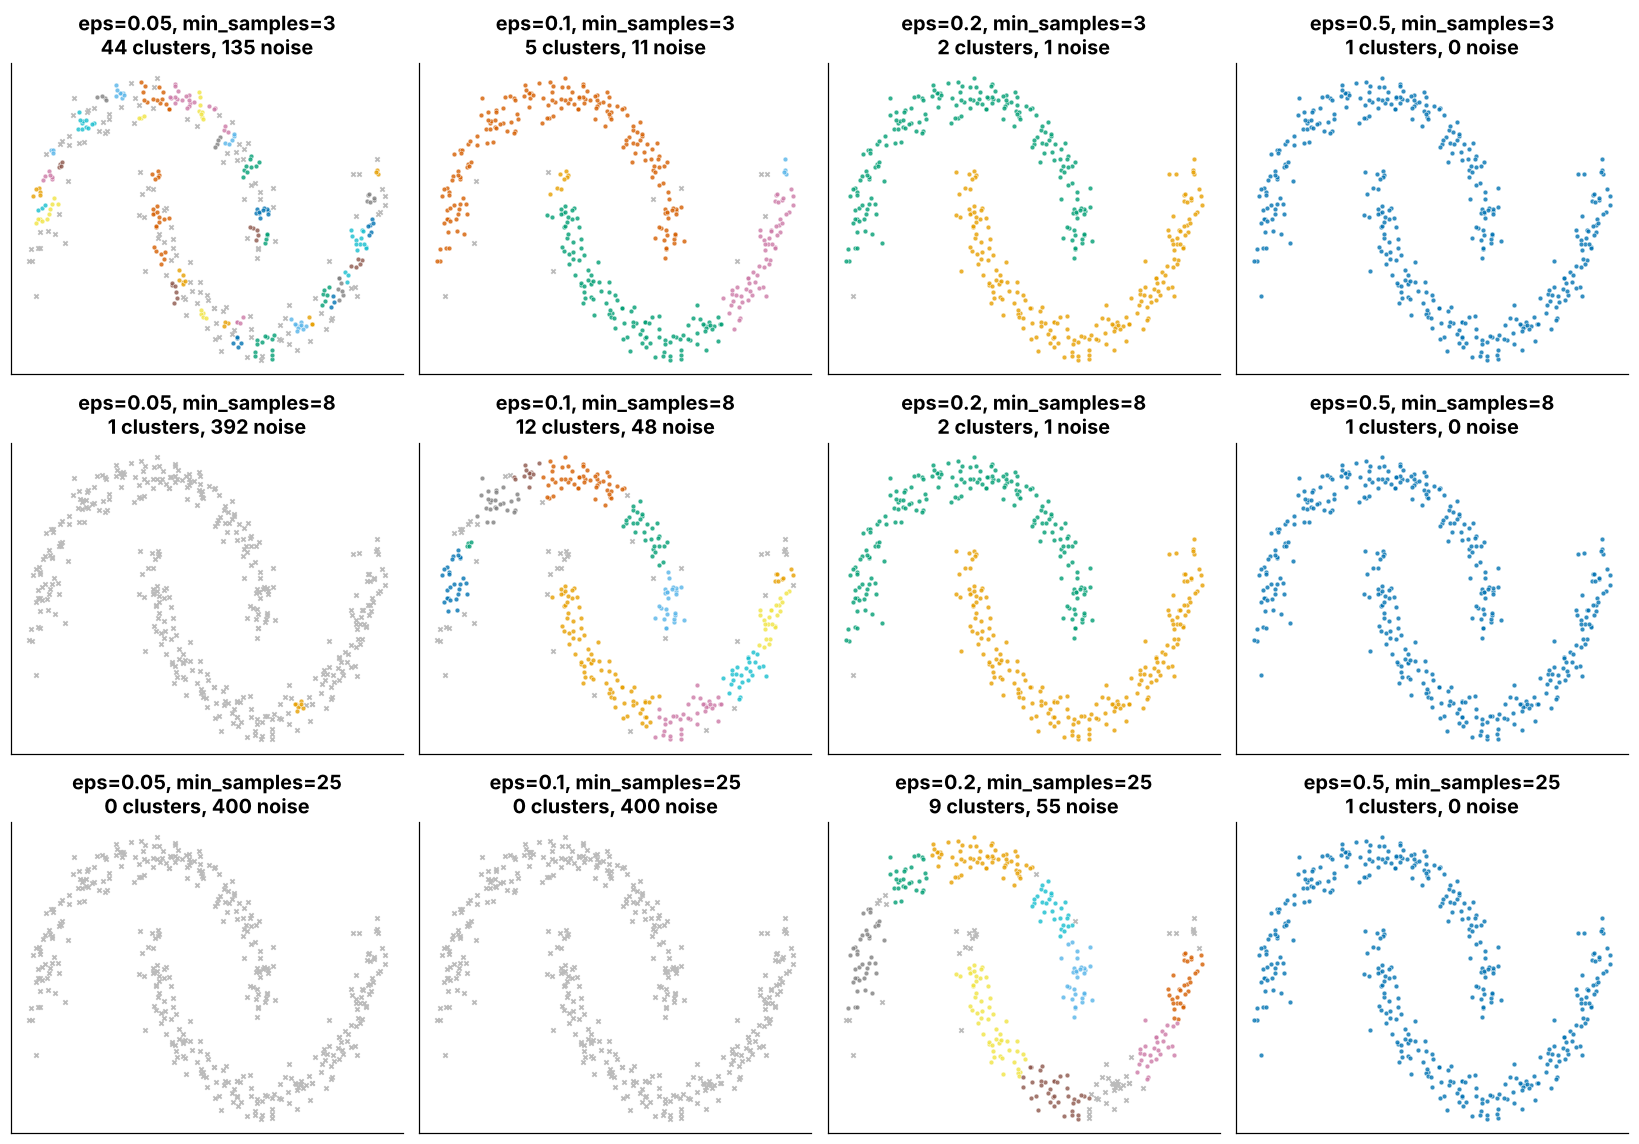

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10.5))
for r, ms in enumerate([3, 8, 25]):
    for c, eps in enumerate([0.05, 0.1, 0.2, 0.5]):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_moons)
        ncl = len(set(lab) - {-1})
        plot_clusters_2d(X_moons, lab, ax=axes[r, c], s=10, title=f"eps={eps}, min_samples={ms}\n{ncl} clusters, {(lab == -1).sum()} noise")
        axes[r, c].legend().set_visible(False); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
plt.tight_layout(); plt.show()

**The pattern:**

| If `eps` is… | You get… |
|---|---|
| **Too small** | Almost everything is noise, or lots of tiny clusters |
| **Too large** | Everything merges into **one giant cluster** |
| **Just right** | The real structure |

`min_samples` acts like a *strictness* dial: larger values demand denser crowds, so more points become noise and small clusters vanish.

### The k-distance plot (a principled way to pick `eps`)

**Idea.** Pick `min_samples` first (rule of thumb: **≥ number of features + 1**; commonly `2 × features`, and bigger for noisy data). For every point, compute the distance to its **`min_samples`-th nearest neighbour**. Sort those distances and plot them.

- Points *inside* clusters have close neighbours → small distances → the flat left side.
- Noise points have far neighbours → big distances → the steep right tail.
- **The "knee" where the curve bends upward is a good `eps`.**

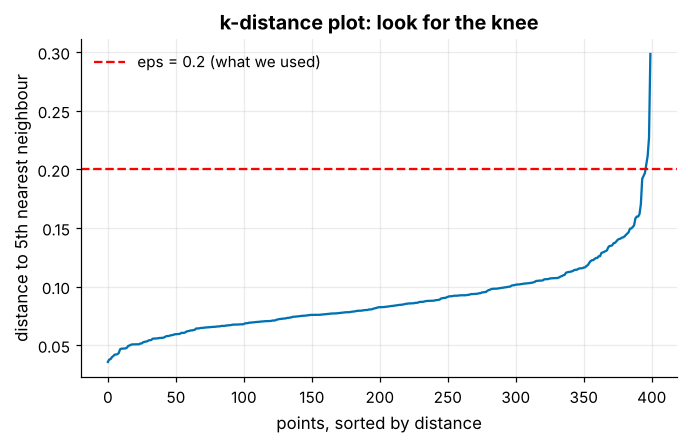

In [6]:
def k_distances(X, k):
    """Sorted distance of every point to its k-th nearest neighbour (self excluded)."""
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)      # +1 because each point is its own nearest neighbour
    dist, _ = nn.kneighbors(X)
    return np.sort(dist[:, k])

kd = k_distances(X_moons, k=5)
plt.figure(figsize=(7, 4))
plt.plot(kd); plt.axhline(0.2, color="red", ls="--", label="eps = 0.2 (what we used)")
plt.xlabel("points, sorted by distance"); plt.ylabel("distance to 5th nearest neighbour")
plt.title("k-distance plot: look for the knee"); plt.legend(); plt.show()

> 🧭 **Pro tip.** The knee is rarely razor-sharp. Treat it as a **starting range**, then try a few `eps` values and **plot the results**. A useful extra check: plot *number of clusters vs eps*. Look for a wide **plateau** where the count doesn't change; that's a stable choice (you'll build this in the challenge).

## 7 · Where DBSCAN struggles ⚠️

### Problem 1: clusters of very different densities
One `eps` for the whole dataset can't fit both a tight cluster and a diffuse one.

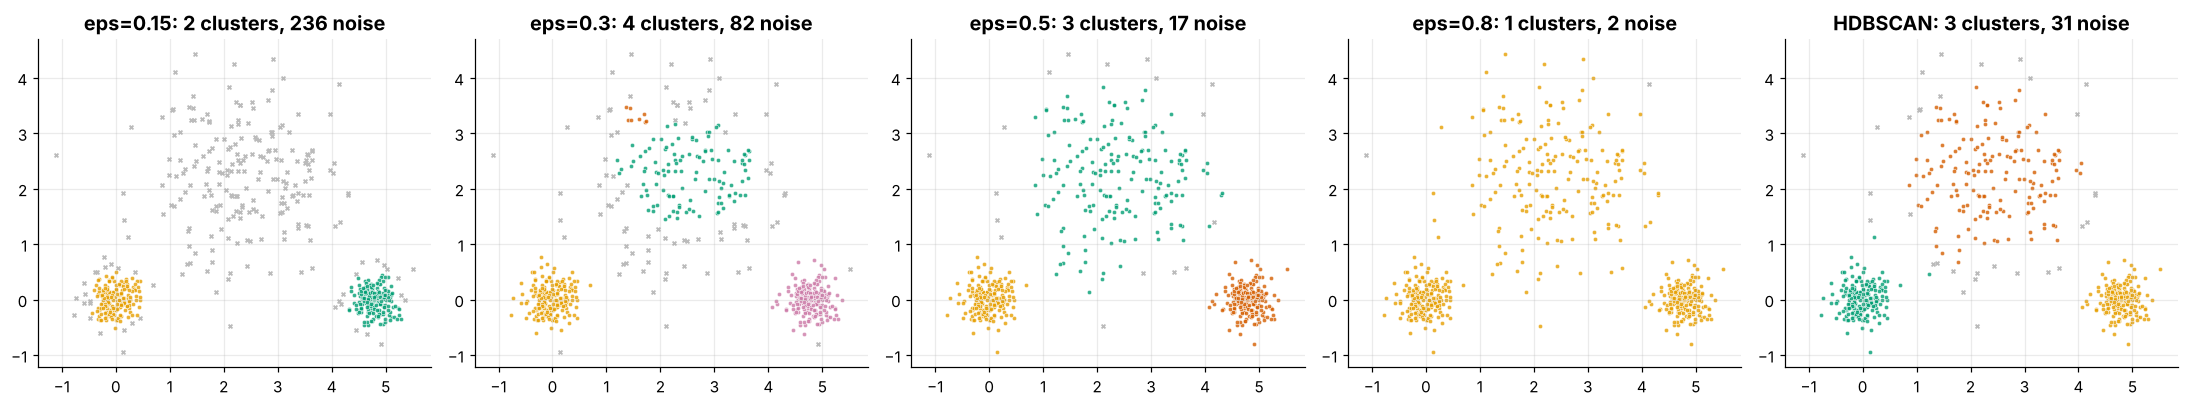

In [7]:
rng = np.random.default_rng(0)
X_var = np.vstack([rng.normal([0, 0], 0.25, (200, 2)),       # tight
                   rng.normal([2.4, 2.2], 0.9, (200, 2)),    # diffuse, and close to its neighbours
                   rng.normal([4.8, 0], 0.25, (200, 2))])    # tight

fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, eps in zip(axes[:4], [0.15, 0.3, 0.5, 0.8]):
    lab = DBSCAN(eps=eps, min_samples=8).fit_predict(X_var)
    plot_clusters_2d(X_var, lab, ax=ax, s=8, title=f"eps={eps}: {len(set(lab) - {-1})} clusters, {(lab == -1).sum()} noise")
    ax.legend().set_visible(False)

from sklearn.cluster import HDBSCAN
lab = HDBSCAN(min_cluster_size=20, copy=True).fit_predict(X_var)
plot_clusters_2d(X_var, lab, ax=axes[4], s=8, title=f"HDBSCAN: {len(set(lab) - {-1})} clusters, {(lab == -1).sum()} noise")
axes[4].legend().set_visible(False)
plt.tight_layout(); plt.show()

Read the panels left to right:
- **eps = 0.15**: the tight clusters survive, but the diffuse cluster **dissolves into noise** (its points are too far apart to count as "crowded").
- **eps = 0.3**: the diffuse cluster **shatters** into fragments, with lots of noise.
- **eps = 0.5**: we get lucky: three clusters!
- **eps = 0.8**: the neighbourhood is now so large that the three clusters **chain together into one**.

So DBSCAN has a **narrow sweet spot** here, and with more extreme density differences there may be *no* single `eps` that works. The panel on the right is **HDBSCAN** (*Hierarchical* DBSCAN, in scikit-learn ≥ 1.3): it considers *all* values of `eps` and keeps the most stable clusters. It recovers three clusters with no `eps` tuning at all. It's often the best modern choice, and well worth learning after this course.

### Problem 2: high dimensions
In 50 dimensions, distances between points all become similar ("the curse of dimensionality"), so "dense" vs "sparse" stops being meaningful. **Remedy:** reduce dimensions first with PCA (Lesson 4!).

### Problem 3: you must scale
Like K-Means, DBSCAN uses distances: standardise the features (except for coordinates you want to keep in physical units; see next).

### Other limits
No `.predict()` for new points; border points can be order-dependent.

## 8 · Worked example 🌾: Where are the clusters of agricultural markets?

**Business question.** A ministry wants to **place regional produce-aggregation hubs**. Step one: *where do markets naturally cluster geographically, and which markets are too remote to be served by any hub?*

DBSCAN is ideal: unknown number of regions, irregular shapes, and *we explicitly want to find the isolated ones*.

In [8]:
markets = load("markets")
print(markets.shape)
markets[["market_name", "latitude", "longitude", "distance_to_city_km", "price_volatility"]].head()

(103, 15)


,market_name,latitude,longitude,distance_to_city_km,price_volatility
0,Nairobi Urban 1,-1.2282,36.8211,5.2,0.165
1,Nairobi Urban 2,-1.2753,36.8454,4.7,0.148
2,Nairobi Regional 3,-1.1616,36.6827,40.5,0.197
3,Nairobi Rural 4,-1.2448,36.9446,86.3,0.370
4,Nairobi Rural 5,-1.1603,36.6597,91.9,0.364


### Latitude/longitude need special care 🌍
Degrees aren't kilometres, and the Earth is round. The right distance for coordinates is the **haversine** (great-circle) distance. In scikit-learn:
- `metric="haversine"` expects coordinates in **radians** → use `np.radians(...)`.
- It returns distances in **radians on a unit sphere**, so `eps` must be **km ÷ 6371** (Earth's radius in km).

This lets us think in kilometres: *"markets within 40 km of each other are neighbours."*

**Choosing eps with the k-distance plot (in km):**

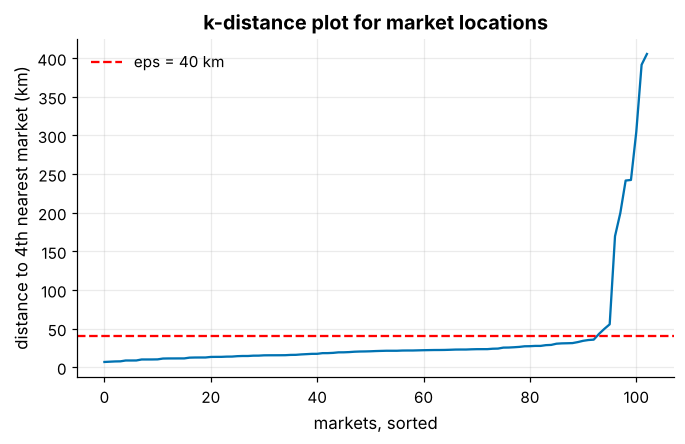

In [9]:
EARTH_R = 6371.0
coords_rad = np.radians(markets[["latitude", "longitude"]].values)

nn = NearestNeighbors(n_neighbors=5, metric="haversine").fit(coords_rad)
d, _ = nn.kneighbors(coords_rad)
kd_km = np.sort(d[:, 4]) * EARTH_R                  # 4th nearest neighbour (index 0 is the point itself), in km

plt.figure(figsize=(7, 4))
plt.plot(kd_km); plt.axhline(40, color="red", ls="--", label="eps = 40 km")
plt.xlabel("markets, sorted"); plt.ylabel("distance to 4th nearest market (km)")
plt.title("k-distance plot for market locations"); plt.legend(); plt.show()

The curve is flat (most markets have 4 neighbours within a few tens of km), then **shoots up** at the right end: those are the isolated markets. A knee around **30–50 km** looks right. We'll use **40 km** and `min_samples = 4`.

In [10]:
db = DBSCAN(eps=40 / EARTH_R, min_samples=4, metric="haversine", algorithm="ball_tree").fit(coords_rad)
markets["geo_cluster"] = db.labels_
n_clusters = len(set(db.labels_) - {-1})
print(f"{n_clusters} geographic clusters; {(db.labels_ == -1).sum()} isolated (noise) markets")
print(markets["geo_cluster"].value_counts().sort_index().to_string())

7 geographic clusters; 7 isolated (noise) markets
geo_cluster
-1     7
 0    22
 1    12
 2    11
 3    13
 4    19
 5    10
 6     9


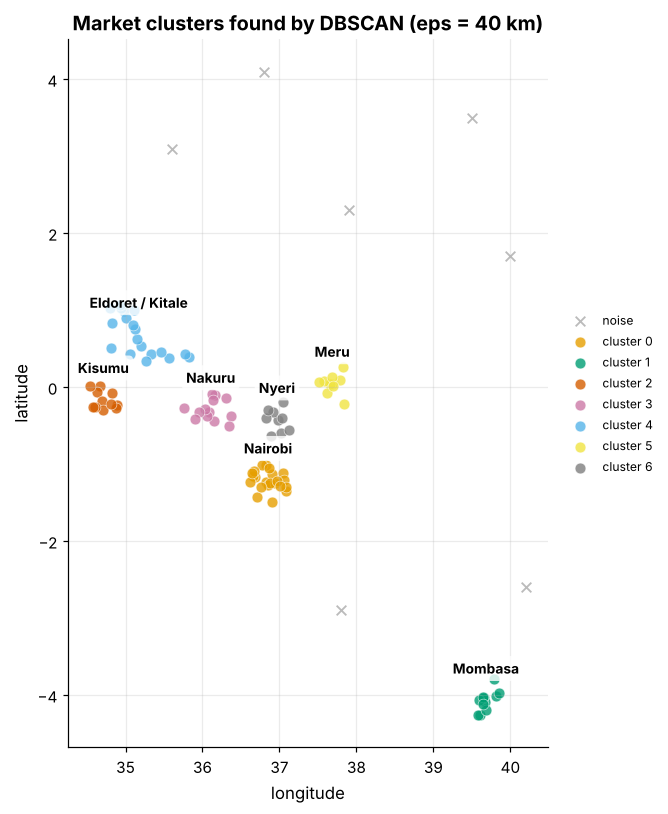

In [11]:
fig, ax = plt.subplots(figsize=(8, 7.5))
plot_clusters_2d(markets[["longitude", "latitude"]].values, markets["geo_cluster"].values, ax=ax, s=50,
                 xlabel="longitude", ylabel="latitude", title="Market clusters found by DBSCAN (eps = 40 km)")
# label each cluster by the hub town most of its members belong to
for c in sorted(set(markets["geo_cluster"]) - {-1}):
    sub = markets[markets["geo_cluster"] == c]
    ax.annotate(" / ".join(sub["nearest_hub"].value_counts().index[:2]), (sub["longitude"].mean(), sub["latitude"].mean() + 0.35),
                ha="center", fontsize=9, fontweight="bold", bbox=dict(boxstyle="round", fc="white", alpha=.8, lw=0))
ax.set_aspect("equal"); ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8); plt.tight_layout(); plt.show()

Beautiful: clusters of different sizes and spreads around Nairobi, Mombasa, Kisumu, Nakuru, Meru, Nyeri, and a combined Eldoret–Kitale region: **plus** isolated markets (grey ×) far from everything.

> 🤔 **Notice:** there are 8 hub towns in our data but only 7 clusters. Which two merged? Look at the plot labels: **Eldoret and Kitale** are only ~60 km apart, and a chain of markets in between links them. Try `eps = 20` km and they separate into 8 clusters: but then **13 more markets** become noise, because 20 km is too strict for sparser regions. That tug-of-war is the essence of tuning `eps`.

### The noise *is* the insight 💡
Let's compare the noise markets with the rest:

In [12]:
markets["is_remote"] = markets["geo_cluster"] == -1
markets.groupby("is_remote")[["distance_to_city_km", "price_volatility", "road_quality_1_5", "avg_daily_traders", "mobile_payment_share"]].mean().round(2)

,distance_to_city_km,price_volatility,road_quality_1_5,avg_daily_traders,mobile_payment_share
is_remote,,,,,
False,54.46,0.26,3.12,330.08,0.59
True,197.99,0.44,1.74,60.43,0.18


The isolated markets are ~**200 km from a city**, with **poor roads**, **tiny trader numbers**, **very volatile prices**, and **low mobile-money use**. A K-Means with *k = 8* would have forced them into some cluster and hidden this. DBSCAN surfaced a distinct, *underserved* population.

> 🌾 **Agricultural lens.** Dense clusters → candidates for **aggregation hubs and cold storage**. Noise points → candidates for **mobile collection trucks, price-information SMS, or road investment**. Two different policies, discovered by one algorithm.

## 9 · 🧩 Your turn: practice problems

### 🧩 Exercise 1: Core, border, noise: by hand
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Using the nine points `P` from Section 3 (with `EPS = 1.5`, `MIN_SAMPLES = 3`), **without calling DBSCAN**, compute:

- `counts`: for every point, how many points (itself included) are within `EPS`
- `core_mask`: a boolean array: `True` where `counts >= MIN_SAMPLES`
- `n_border`: number of **border** points (not core, but within `EPS` of at least one core point)
- `n_noise`: number of **noise** points (neither)

*(Section 3 showed some of these, but write the code to compute them yourself, in a way that works for any dataset.)*

<details><summary>💡 Hint 1</summary>

You already have the distance matrix `D`. `(D <= EPS)` is a boolean matrix; `.sum(axis=1)` counts neighbours per row.

</details>
<details><summary>💡 Hint 2</summary>

To check *'within EPS of a core point'*: `(D[:, core_mask] <= EPS).any(axis=1)`: for each point, is at least one core point within reach?

</details>
<details><summary>💡 Hint 3</summary>

`border_mask = ~core_mask & near_core`; `noise_mask = ~core_mask & ~near_core`. Count with `.sum()`.

</details>

In [13]:
# YOUR CODE HERE  (P, D, EPS, MIN_SAMPLES already exist)

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('the first five points each have [4 5 4 5 4] points in reach', lambda: list(counts[:5]) == [4, 5, 4, 5, 4])
check('5 core points', lambda: core_mask.sum() == 5)
check('1 border point', lambda: n_border == 1)
check('3 noise points', lambda: n_noise == 3)
check('agrees with scikit-learn on core points', lambda: set(np.where(core_mask)[0]) == set(db_hand.core_sample_indices_))

### 🧩 Exercise 2: Rescue the moons
**Difficulty:** ⭐  |  **Time:** ~8 min

Find **`eps`** (with `min_samples=5`) so that DBSCAN on `X_moons` finds **exactly 2 clusters** and the Adjusted Rand Index against the true labels `y_moons` is **≥ 0.95**.

Store your choice in `my_eps`, and the labels in `my_labels`. 

*Experiment: loop over `eps` values from 0.05 to 0.5 and print the number of clusters and ARI for each. Which values work? Which fail, and why?*

<details><summary>💡 Hint 1</summary>

`for eps in np.arange(0.05, 0.5, 0.05): ...` and `DBSCAN(eps=eps, min_samples=5).fit_predict(X_moons)`.

</details>
<details><summary>💡 Hint 2</summary>

Count clusters with `len(set(labels) - {-1})` (don't count the noise label −1 as a cluster).

</details>
<details><summary>💡 Hint 3</summary>

Too-small eps → many tiny clusters + noise. Too-large eps → 1 cluster. Pick one from the middle of the 'works' range.

</details>

In [15]:
# YOUR CODE HERE
# my_eps = ...
# my_labels = DBSCAN(eps=my_eps, min_samples=5).fit_predict(X_moons)

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('exactly 2 clusters', lambda: len(set(my_labels) - {-1}) == 2)
check('ARI >= 0.95 against the truth', lambda: adjusted_rand_score(y_moons, my_labels) >= 0.95)

### 🧩 Exercise 3: Build a k-distance curve and pick eps
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

1. Using the helper `k_distances(X, k)` from Section 6, compute `kd_moons = k_distances(X_moons, k=5)`.
2. Set `eps_guess` to the **95th percentile** of `kd_moons` (a simple, robust stand-in for "the knee").
3. Run DBSCAN with `eps=eps_guess, min_samples=5` and store the number of clusters in `n_clusters_guess`.

Is a purely automatic guess good enough here?

<details><summary>💡 Hint 1</summary>

`np.percentile(kd_moons, 95)` returns the value below which 95% of the distances lie.

</details>
<details><summary>💡 Hint 2</summary>

Number of clusters: `len(set(labels) - {-1})`.

</details>
<details><summary>💡 Hint 3</summary>

Why the 95th percentile? The top ~5% of distances are the noise-like tail; the other 95% describe the dense areas. We pick the edge of the dense part.

</details>

In [17]:
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('kd_moons has one value per point, sorted', lambda: len(kd_moons) == 400 and np.all(np.diff(kd_moons) >= 0))
check('eps_guess is a sensible size (0.05 – 0.3)', lambda: 0.05 < eps_guess < 0.3)
check('it finds 2 clusters', lambda: n_clusters_guess == 2)

### 🧩 Exercise 4: Geographic clusters: tune the radius
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Reuse `coords_rad` and `EARTH_R` from the worked example.

1. Run DBSCAN with `eps = 20 km`, `min_samples = 4` (haversine). Record `n_clusters_20` and `n_noise_20`.
2. Repeat with `eps = 60 km` → `n_clusters_60` and `n_noise_60`.
3. In a comment, explain what changed and why. Which setting would you give the ministry?

*(Remember: eps must be in radians → `km / EARTH_R`.)*

<details><summary>💡 Hint 1</summary>

`DBSCAN(eps=20 / EARTH_R, min_samples=4, metric='haversine', algorithm='ball_tree').fit_predict(coords_rad)`

</details>
<details><summary>💡 Hint 2</summary>

Cluster count: `len(set(labels) - {-1})`. Noise count: `(labels == -1).sum()`.

</details>
<details><summary>💡 Hint 3</summary>

Compare with the 40 km result (7 clusters, 7 noise). At 20 km the criterion is stricter; at 60 km neighbouring regions chain together.

</details>

In [19]:
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('at 20 km: 8 clusters', lambda: n_clusters_20 == 8)
check('at 20 km: many more than 7 markets are noise', lambda: n_noise_20 > 7)
check('at 60 km: fewer than 7 clusters (regions have merged)', lambda: n_clusters_60 < 7)
check('at 60 km: only the 7 remote markets are noise', lambda: n_noise_60 == 7)

### 🧩 Exercise 5: Interrogate the noise
**Difficulty:** ⭐  |  **Time:** ~6 min

Using `markets` with its `is_remote` column (from the worked example), compute:

- `remote_mean_dist` and `clustered_mean_dist`: the mean `distance_to_city_km` for remote vs non-remote markets
- `remote_mean_roads` and `clustered_mean_roads`: the mean `road_quality_1_5`
- `remote_share_cold`: share of remote markets with `has_cold_storage == 1`

Then write (in a comment) **one sentence of policy advice** for the ministry.

<details><summary>💡 Hint 1</summary>

`markets[markets['is_remote']]['distance_to_city_km'].mean()` for remote; use `~markets['is_remote']` for the others.

</details>
<details><summary>💡 Hint 2</summary>

A share of 0/1 values = its `.mean()`.

</details>

In [21]:
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('remote markets are much farther from cities', lambda: remote_mean_dist > 2 * clustered_mean_dist)
check('remote markets have worse roads', lambda: remote_mean_roads < clustered_mean_roads)
check('none of the remote markets has cold storage', lambda: remote_share_cold == 0)

### 🧩 Exercise 6: 🏆 Challenge: find the stable plateau automatically
**Difficulty:** ⭐⭐⭐  |  **Time:** ~20 min

Write `stable_eps(X, min_samples, grid)` that:

1. Runs DBSCAN for every `eps` in `grid`, recording the **number of clusters** (noise excluded).
2. Ignores any `eps` giving **fewer than 2** clusters.
3. Finds the **longest run of consecutive grid values with the same cluster count**.
4. Returns the **middle** `eps` of that run.

Test: `stable_eps(X_moons, 5, np.arange(0.05, 0.6, 0.01))` should give a value where DBSCAN finds 2 clusters.

<details><summary>💡 Hint 1</summary>

First build `counts = [len(set(DBSCAN(eps=e, min_samples=min_samples).fit_predict(X)) - {-1}) for e in grid]`.

</details>
<details><summary>💡 Hint 2</summary>

Scan through `counts` keeping `start` and `length` of the current run. When `counts[i] != counts[i-1]`, a new run starts.

</details>
<details><summary>💡 Hint 3</summary>

Skip runs where the count is below 2: only compare lengths when `counts[start] >= 2`. The answer is `grid[start + length // 2]`.

</details>
<details><summary>💡 Hint 4</summary>

Alternative: `itertools.groupby(enumerate(counts), key=lambda t: t[1])` groups consecutive equal counts for you.

</details>

In [23]:
def stable_eps(X, min_samples, grid):
    # YOUR CODE HERE
    pass

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('returns an eps inside the grid', lambda: 0.05 <= stable_eps(X_moons, 5, np.arange(0.05, 0.6, 0.01)) <= 0.6)
check('DBSCAN at that eps finds exactly 2 moons', lambda: len(set(DBSCAN(eps=stable_eps(X_moons, 5, np.arange(0.05, 0.6, 0.01)), min_samples=5).fit_predict(X_moons)) - {-1}) == 2)

### 🎯 Check your understanding
*Try to answer each question out loud or on paper before you peek.*

**Q1.** In DBSCAN, what is the difference between a core point and a border point?

<details><summary>Show answer</summary>

A **core** point has at least `min_samples` points (itself included) within distance `eps`. A **border** point has fewer, but lies within `eps` of a core point. Core points can extend a cluster; border points only join it.

</details>

**Q2.** What does the label −1 mean, and why is it valuable?

<details><summary>Show answer</summary>

It marks **noise**: points not in any dense region. It's valuable because K-Means and hierarchical clustering *force* every point into a cluster; DBSCAN lets outliers be outliers, and outliers are often the most interesting rows (fraud, remote markets, data errors).

</details>

**Q3.** You run DBSCAN and get one giant cluster containing 98% of the data. What do you change?

<details><summary>Show answer</summary>

`eps` is probably too **large** (or `min_samples` too small), so everything chains together. Decrease `eps`, or increase `min_samples`. Use the k-distance plot to calibrate.

</details>

**Q4.** You run DBSCAN and 90% of points are labelled noise. What do you change?

<details><summary>Show answer</summary>

`eps` is too **small** (or `min_samples` too large). Increase `eps`, or reduce `min_samples`; check that features are scaled.

</details>

**Q5.** Why is DBSCAN a poor choice for a dataset with a dense cluster and a very diffuse cluster? What can you use instead?

<details><summary>Show answer</summary>

A single `eps` can't suit both densities: small `eps` shreds the diffuse cluster into noise; large `eps` merges the dense clusters with their surroundings. Use **HDBSCAN** (or OPTICS), which handle varying densities.

</details>

**Q6.** Why must we pass radians (and `eps = km / 6371`) when clustering latitude/longitude with the haversine metric?

<details><summary>Show answer</summary>

scikit-learn's haversine metric works on a unit sphere with angles in radians. Distances come out in *radians of arc*; multiplying by Earth's radius (≈6371 km) converts to km, so dividing km by 6371 converts our desired radius to the metric's units.

</details>

## 10 · Summary & cheat sheet 📝

| Concept | Remember |
|---|---|
| **Density-based clustering** | Clusters = dense regions separated by sparse ones |
| **`eps`** | Neighbourhood radius: pick via k-distance knee + plateau checking |
| **`min_samples`** | Crowd size: start at `2 × n_features`, larger for noisy data |
| **Core / border / noise** | Crowd member / fringe / loner (label −1) |
| **Strengths** | No *k*; any shape; finds outliers |
| **Weaknesses** | Varying density; high dimensions; no `.predict()`; sensitive parameters |
| **Haversine** | For lat/lon: radians in, `eps = km/6371` |
| **Upgrade** | `HDBSCAN` for varying density, fewer parameters |

```python
from sklearn.cluster import DBSCAN
labels = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_scaled)      # label -1 = noise
n_clusters = len(set(labels) - {-1})

# Geographic version
DBSCAN(eps=40/6371, min_samples=4, metric="haversine", algorithm="ball_tree").fit_predict(np.radians(latlon))
```

### 🧠 K-Means vs Hierarchical vs DBSCAN: one table to rule them all

| | **K-Means** | **Hierarchical** | **DBSCAN** |
|---|---|---|---|
| Choose *k*? | Yes | After seeing tree | No |
| Shapes | Round | Linkage-dependent | Any |
| Outliers | Distorts | Distorts (esp. single) | **Labels as noise** |
| Scales to big *n* | ✅✅ | ❌ | ✅ (with index structures) |
| Predict new points | ✅ | ❌ | ❌ |
| Key parameter(s) | *k* | linkage, cut | `eps`, `min_samples` |

### 📚 Next up
**Lesson 4: PCA:** your data has 14 columns, but your screen has 2 dimensions. How do we *see*, and simplify, high-dimensional data? 🔭